### 다중 분류 실습 문제

## Intel Image Dataset
: 자연 풍경 및 도시 환경 사진을 6개 클래스로 분류하는 이미지 데이터셋

- 학습데이터 : 약 14,000
- 테스트 데이터 : 약 3,000
- 예측용 데이터 : 약 7,000
- 이미지 크기 : 150 x 150(컬러 이미지)
- 입력 이미지 : RGB 이미지 (64× 64로 크기 변경)
- 입력 특징 수: 3 × 64 × 64 = 3,072
- 출력 클래스: 6개

| 클래스 이름 | 의미 |
|:---:|:---|
| `buildings` | 건물 |
| `forest` | 숲 |
| `glacier` | 빙하 |
| `mountain` | 산 |
| `sea` | 바다 |
| `street` | 거리 |

#### STEP 1. 데이터 불러오기 및 전처리

**실습 조건**
- `torchvision.datasets.ImageFolder`를 이용해 학습 데이터와 테스트 데이터를 불러온다.
- 이미지를 `(64, 64)` 크기로 통일한다.
- `transforms.ToTensor()`를 이용해 Tensor로 변환한다.
- RGB 이미지이므로 이미지 한 장의 형태는 `[3, 64, 64]`이다.
- `ImageFolder`가 부여한 클래스 인덱스와 클래스 이름을 확인한다.
- 학습 데이터와 테스트 데이터의 클래스 순서가 같은지 확인한다.
- 데이터 개수와 첫 번째 이미지의 shape을 출력한다.

In [ ]:
# 데이터를 다운로드 하려면 설치 필요
# %pip install kagglehub

In [7]:
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/Colab Notebooks')

from multiclass_functions import * # all
import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import kagglehub
import shutil
import os
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(DEVICE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cpu


In [8]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 10
criterion = nn.CrossEntropyLoss()
new_model_train = True
model_type = "MLP_shallow"
dataset = "intel_image"

save_dir = "/content/drive/MyDrive/Colab Notebooks/results"
os.makedirs(save_dir, exist_ok=True)

save_model_path = f"{save_dir}/{model_type}_{dataset}.pt"

In [9]:
# Google Drive 저장 위치
data_dir = '/content/drive/MyDrive/Colab Notebooks/data/intel_image'

if os.path.exists(os.path.join(data_dir, 'seg_train')):
  print('이미 데이터가 존재합니다')
else :
  # 1. KaggleHub에서 데이터셋 가져오기
  dataset_path = kagglehub.dataset_download(
      "puneet6060/intel-image-classification"
  )

  print("Kaggle 데이터 위치:", dataset_path)

  # 2. Google Drive에 복사
  os.makedirs(data_dir, exist_ok=True)

  shutil.copytree(
      dataset_path,
      data_dir,
      dirs_exist_ok=True
  )

  print("Google Drive 저장 완료!")

이미 데이터가 존재합니다


In [11]:
# 이미지 전처리 및 Totensor() 설정
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])
train_DS = datasets.ImageFolder(
    root=f'{data_dir}/seg_train/seg_train',
    transform=transform
)

test_DS = datasets.ImageFolder(
    root=f'{data_dir}/seg_test/seg_test',
    transform=transform
)

train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=False)

In [12]:
print("클래스:", train_DS.classes)
print("클래스 인덱스:", train_DS.class_to_idx)
print("학습 데이터 개수:", len(train_DS))
print("테스트 데이터 개수:", len(test_DS))

클래스: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
클래스 인덱스: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}
학습 데이터 개수: 14034
테스트 데이터 개수: 3000


#### STEP 2. DataLoader 생성 및 데이터 확인

**실습 조건**
- 학습률(LR): `1e-3`
- Epoch: 10 이상
- Batch size: 32
- Optimizer: Adam
- Loss function: CrossEntropyLoss
- 학습 데이터는 `shuffle=True`, 테스트 데이터는 `shuffle=False`로 설정한다.
- 첫 번째 배치의 `x_batch`, `y_batch` shape을 확인한다.
- 이미지를 시각화하고 이미지의 클래스 이름을 표시한다.

x_batch: torch.Size([32, 3, 64, 64])
mountain


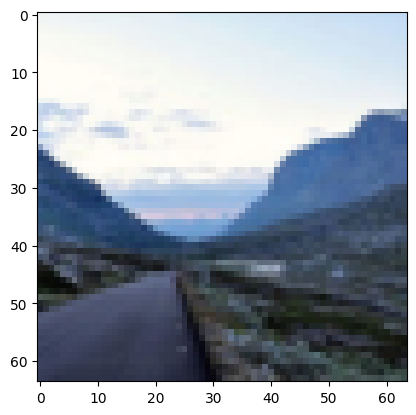

In [13]:
train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=False)

x_batch, y_batch = next(iter(train_DL))
print("x_batch:", x_batch.shape)  # [batch_size, 3, 64, 64]

# 이미지 1장
plt.imshow(x_batch[0].permute(1,2,0))
print(test_DS.classes[y_batch[0]])

#### STEP 3. MLP 모델 만들기

**모델 조건**

- 입력 이미지 크기: `[3, 64, 64]`
- `torch.flatten(x, start_dim=1)`을 이용해 배치 차원은 유지하고 나머지 차원을 펼친다.
- 입력 특징 수: `3 × 64 × 64`<br><br>

- 3가지의 모델 정의하기
    1. 은닉층 노드 수: 30개
    2. 은닉층 노드 수: 100개
    3. 여러개의 은닉층

In [14]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear = nn.Sequential(
            nn.Linear(3*64*64, 30),
            nn.BatchNorm1d(30),
            nn.ReLU(),
            nn.Linear(30, 6)
        )

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = self.linear(x)
        return x

class MLP_shallow(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Sequential(nn.Linear(3*64*64, 100),
                                    nn.BatchNorm1d(100),
                                    nn.ReLU(),
                                    nn.Linear(100, 6))
    def forward(self,x):
        x = torch.flatten(x, start_dim=1)
        x = self.linear(x)
        return x

class MLP_deep(nn.Module):
  def __init__(self):
      super().__init__()
      self.linear = nn.Sequential(nn.Linear(3*64*64, 75),
                                  nn.BatchNorm1d(75),
                                  nn.ReLU(),
                                  *[i for _ in range(10) for i in [nn.Linear(75, 75), nn.BatchNorm1d(75), nn.ReLU()]],
                                  nn.Linear(75, 6))
  def forward(self,x):
      x = torch.flatten(x, start_dim=1)
      x = self.linear(x)
      return x

In [15]:
model = globals()[model_type]().to(DEVICE)
print(model)

MLP_shallow(
  (linear): Sequential(
    (0): Linear(in_features=12288, out_features=100, bias=True)
    (1): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=100, out_features=6, bias=True)
  )
)


#### STEP 4. 모델 학습시키고 저장하기

Epoch : 1, train loss : 1.226
--------------------
Epoch : 2, train loss : 1.075
--------------------
Epoch : 3, train loss : 1.006
--------------------
Epoch : 4, train loss : 0.942
--------------------
Epoch : 5, train loss : 0.895
--------------------
Epoch : 6, train loss : 0.851
--------------------
Epoch : 7, train loss : 0.798
--------------------
Epoch : 8, train loss : 0.747
--------------------
Epoch : 9, train loss : 0.721
--------------------
Epoch : 10, train loss : 0.677
--------------------


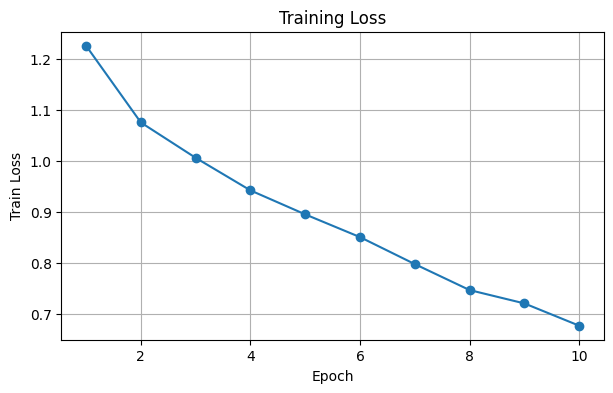

In [16]:
if new_model_train:
  optimizer = optim.Adam(model.parameters(), lr=LR)
  loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

  torch.save(model, save_model_path)

  plt.figure(figsize=(7, 4))
  plt.plot(range(1, EPOCH + 1), loss_history, marker="o")
  plt.xlabel("Epoch")
  plt.ylabel("Train Loss")
  plt.title("Training Loss")
  plt.grid()

#### STEP 5. 테스트 및 그래프

In [17]:
load_model = torch.load(save_model_path, map_location=DEVICE, weights_only=False)

Test(load_model, test_DL)
print(count_params(load_model))

Test accuracy : 1763 / 3000 (58.8 %)
1229706


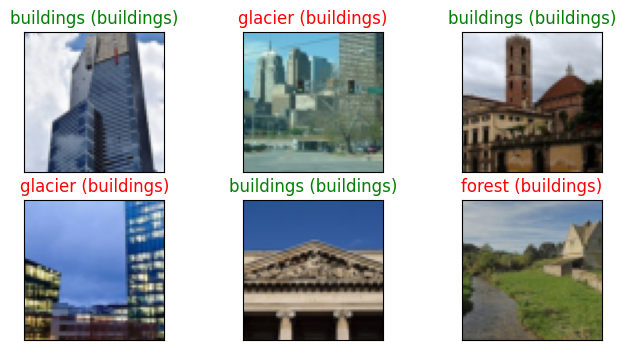

In [18]:
Test_plot(load_model,test_DL)

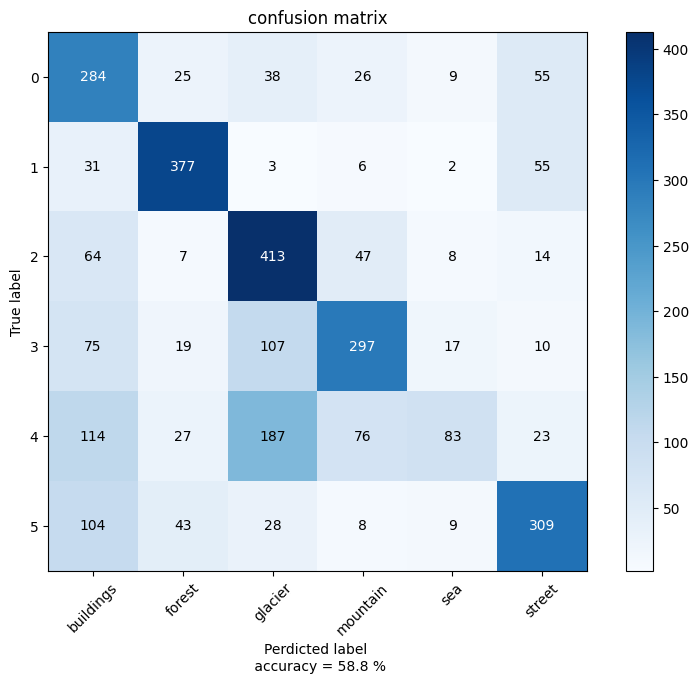

In [19]:
confusion = get_conf(load_model, test_DL)
plot_confusion_matrix(confusion, test_DS.classes)
plt.xticks(rotation=45);

#### STEP 7. 모델 파라미터 개수 확인

In [20]:
count_params(model)

1229706

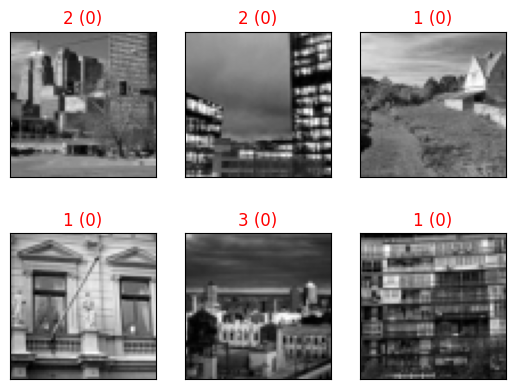

In [ ]:
cnt = 0
load_model.eval()

with torch.no_grad():
  for x_batch, y_batch in test_DL :
    x_batch = x_batch.to(DEVICE)
    y_batch = y_batch.to(DEVICE)
    y_hat = load_model(x_batch)
    pred = y_hat.argmax(dim=1)

    false_idx = pred != y_batch
    X_false = x_batch[false_idx,...].to('cpu')
    pred_false = pred[false_idx,...].to('cpu')
    Y_false = y_batch[false_idx,...].to('cpu')

    if X_false.shape[0] != 0:
      if cnt == 6:
        break
      for i in range(X_false.shape[0]):
        cnt += 1
        pred_class = pred_false[i].item()
        true_class = Y_false[i].item()

        pred_name = test_DS.classes[pred_class]
        ture_name = test_DS.classes[true_class]

        plt.subplot(2,3, cnt, xticks=[], yticks=[])
        plt.imshow(X_false[i,0,...], cmap='gray')
        plt.title(f'{pred_name} ({ture_name})', color='r')
        if cnt == 6:
          break